# House prices: regression with MLflow

How much is a house in California worth? We train 7 regression models and save every one of
them to MLflow with `RegressionTracker` (from `regression.py`).

The data is the California Housing dataset (1990 census, 20,640 districts). The target
`MedHouseVal` is the median house value in units of $100,000.

In [1]:
import os
import sys
import warnings

# work from the project folder: data/, mlflow.db and the .py files live there
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

# quieter output: no progress bars, hints or MLflow info messages
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore")

In [2]:
import logging

import mlflow
import pandas as pd
from IPython.display import display
from lightgbm import LGBMRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

from regression import RegressionTracker

mlflow.set_tracking_uri("sqlite:///mlflow.db")
logging.getLogger("mlflow").setLevel(logging.ERROR)  # after the import: mlflow resets it

## 1. Data

8 numeric features (income, house age, rooms, location...). The split is 80% train / 20% test.

In [3]:
df = pd.read_csv("data/house_prices.csv")
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"train: {len(X_train)} rows, test: {len(X_test)} rows")
df.head()

train: 16512 rows, test: 4128 rows


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Models

From the simplest (a straight line) to boosted trees.

In [4]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=42
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1
    ),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, random_state=42
    ),
    "K-Nearest Neighbors": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
}

## 3. Train and track

Each model gets its own MLflow run (named `<project>_<model>_<date>_<time>`) with the
train and test datasets, the model, all its hyperparameters and learned parameters, the metrics
(MAE, RMSE, R²), 4 charts about the predictions and errors, a learning curve and two SHAP charts. A model that was already saved is skipped.
At the end, the top 5 models are compared in a "Top 5 comparison" run with 7 charts (only when the top 5 changed).

In [5]:
tracker = RegressionTracker(
    "house_prices", X_train, X_test, y_train, y_test, data_source="data/house_prices.csv"
)
tracker.run_all(models).round(3)

[Linear Regression] saved


[Decision Tree] saved


[Random Forest] saved


[LightGBM] saved


[XGBoost] saved


[Gradient Boosting] saved


[K-Nearest Neighbors] saved


Top 5 comparison saved (best: LightGBM)


,model,mae,rmse,r2
0,Linear Regression,0.533,0.746,0.576
1,Decision Tree,0.445,0.645,0.682
2,Random Forest,0.345,0.525,0.790
3,LightGBM,0.297,0.450,0.846
4,XGBoost,0.306,0.465,0.835
5,Gradient Boosting,0.301,0.453,0.843
6,K-Nearest Neighbors,0.440,0.649,0.678


## 4. Compare the models (lowest RMSE first)

In [6]:
tracker.top_models().drop(columns=["run_id", "model_id"]).round(3)

,model,mae,rmse,r2
0,LightGBM,0.297,0.450,0.846
1,Gradient Boosting,0.301,0.453,0.843
2,XGBoost,0.306,0.465,0.835
3,Random Forest,0.345,0.525,0.790
4,Decision Tree,0.445,0.645,0.682


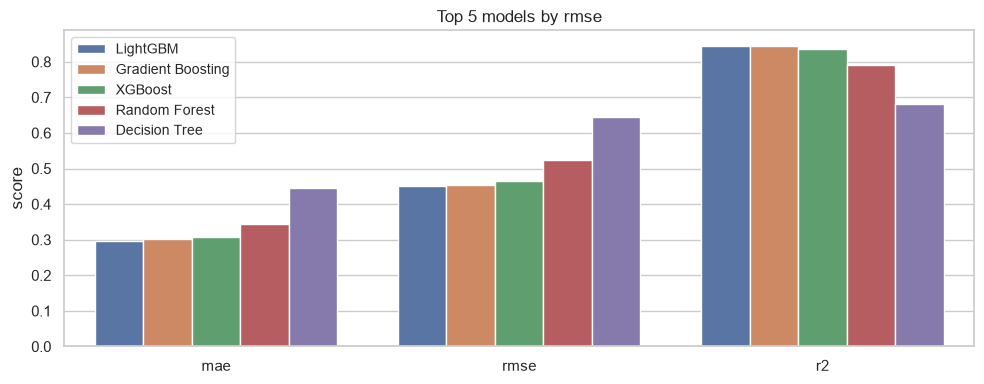

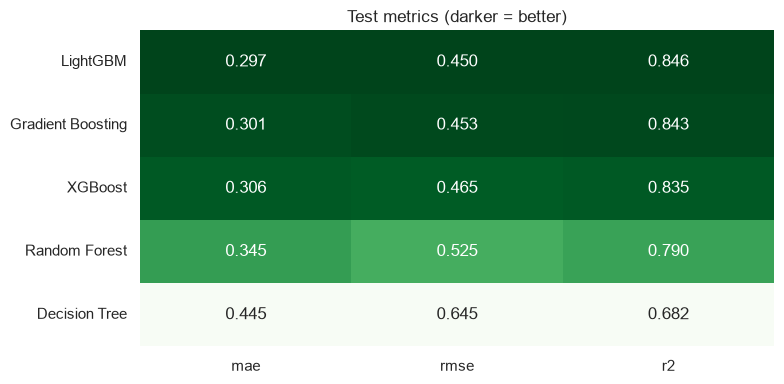

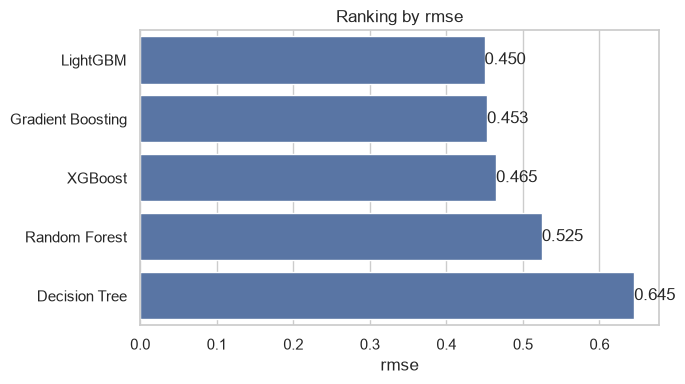

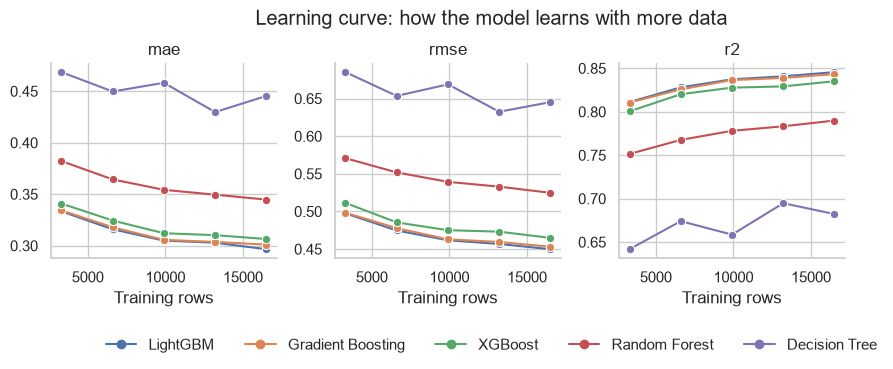

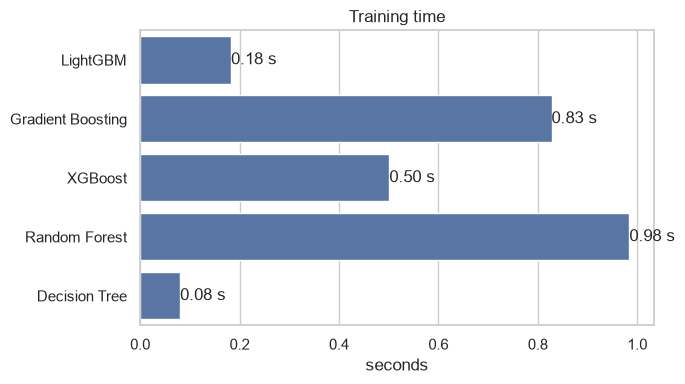

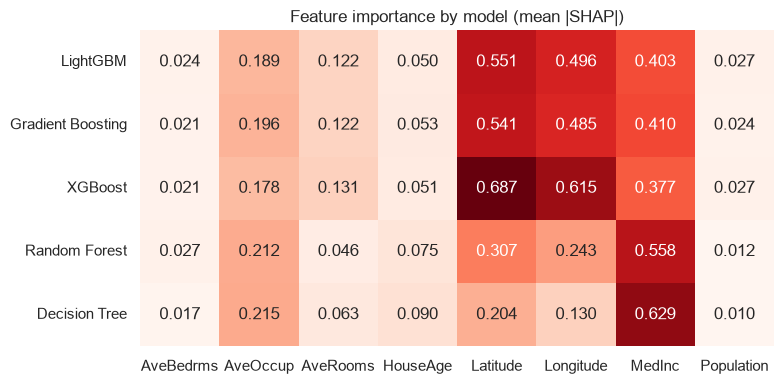

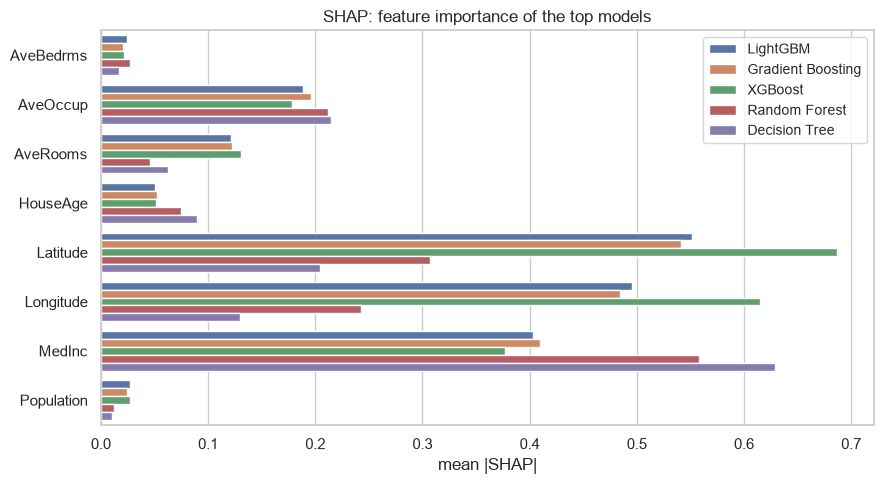

In [7]:
for chart in tracker.comparison_charts().values():
    display(chart)

## 5. Use the best model on houses it has never seen

In [8]:
model, best = tracker.load_best_model()
print(f"Best model: {best['model']} (RMSE = {best['rmse']:.3f}, R² = {best['r2']:.3f})")

houses = X_test.head(5).copy()
houses["actual ($)"] = (y_test.head(5) * 100_000).round(-3)
houses["predicted ($)"] = (model.predict(X_test.head(5)) * 100_000).round(-3)
houses

Best model: LightGBM (RMSE = 0.450, R² = 0.846)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,actual ($),predicted ($)
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,48000.0,58000.0
3024,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,46000.0,90000.0
15663,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,500000.0,486000.0
20484,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,219000.0,240000.0
9814,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,278000.0,252000.0


## 6. Production: score 5 rows from the data feed

In production, a separate service does not need this notebook, the tracker or the training
code: it loads the model from MLflow **by its id** and calls `predict`. The MLflow model also
checks that the input has the right columns (its signature).

In [9]:
production_model = mlflow.pyfunc.load_model(f"models:/{best['model_id']}")

feed = df.sample(5, random_state=7)  # 5 rows arriving from the data feed
scored = feed.copy()
scored["predicted"] = production_model.predict(feed.drop(columns="MedHouseVal")).round(3)
scored["error ($)"] = ((scored["predicted"] - scored["MedHouseVal"]) * 100_000).round(-3)
scored

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,predicted,error ($)
4648,2.0278,31.0,2.846928,1.091641,3107.0,3.128902,34.06,-118.31,3.60000,2.879,-72000.0
8740,4.3056,30.0,5.036932,1.011364,905.0,2.571023,33.81,-118.31,3.36000,2.930,-43000.0
162,3.6750,52.0,4.851351,0.969112,1048.0,2.023166,37.81,-122.24,2.69900,2.670,-3000.0
15735,2.6392,26.0,3.832265,1.104701,1821.0,1.945513,37.78,-122.43,2.87500,3.219,34000.0
18380,9.1974,23.0,8.075949,0.965190,916.0,2.898734,37.21,-121.86,5.00001,4.859,-14000.0


## 7. Open the MLflow UI

From the project folder, run:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

and open http://127.0.0.1:5000. Each model is a run with its datasets, hyperparameters,
metrics, charts, SHAP files and the model itself. The "Top 5 comparison" run compares the best models.

Run this notebook again: every model prints `nothing changed -> skipped`.